# Sesión Titanic — Seaborn, Plotly, EDA y preparación para ML

**Nombre:** Francisco Javier Porta Borge 
**Fecha:**  09/11/2026

Sesión de 3 horas. Trabaja en pareja, pero entrega tu propio cuaderno. Base: apartados 0–3, ticket y registro. El apartado 4 de ML es ampliación guiada solo si se llega; si no, anota pendiente.

- **Dataset:** `titanic.csv` local (891 filas). No hay que descargar nada.
- **Entrega:** cuaderno ejecutado + HTML de Plotly.
- **Valoración:** hecho/no hecho y checklist; no es una prueba.
- **Ficha de entrega:** [entrega-titanic.md](entrega-titanic.md).

La pregunta conductora: **¿qué perfiles sobrevivieron más y qué habría que preparar antes de intentar predecir la supervivencia?**


## 0. Preparación

Ejecuta esta celda una vez. Comprueba que el kernel es el entorno `ud2` del curso. Si falla un import, anota el error y revisa el entorno; no instales en el Python del sistema.

Si descargas archivos sueltos desde Moodle, coloca `titanic.csv` junto al cuaderno. Con el repositorio completo, conserva las carpetas. Los checkpoints se ejecutan después de resolver su apartado; son ayuda, no una nota ni garantía de buena interpretación.


In [21]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly
import plotly.express as px
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
relativa = Path("05-recursos/datasets/titanic.csv")
candidatos = [Path("titanic.csv"), Path("datasets/titanic.csv"), relativa, Path("..") / relativa, Path("02-tratamiento-datos") / relativa]
ruta = next((p for p in candidatos if p.is_file()), None)
if ruta is None:
    raise FileNotFoundError("No encuentro titanic.csv. Descarga el CSV de la sesión y ponlo junto al cuaderno, o conserva las carpetas de UD2.")
titanic = pd.read_csv(ruta)
titanic["Survived_label"] = titanic["Survived"].map({0: "No", 1: "Sí"})

print("Python:", sys.executable)
print("pandas:", pd.__version__, "| Seaborn:", sns.__version__, "| Plotly:", plotly.__version__)
print("Ruta:", ruta.resolve())
print("Filas y columnas:", titanic.shape)
print(titanic.isna().sum().sort_values(ascending=False).head(6))
assert titanic.shape[0] == 891
assert {"Survived", "Sex", "Pclass", "Age", "Fare", "Embarked"}.issubset(titanic.columns)
titanic.head()

Python: c:\Users\ia\Desktop\IABD\.venv\Scripts\python.exe
pandas: 3.0.6 | Seaborn: 0.13.2 | Plotly: 7.1.0
Ruta: C:\Users\ia\Desktop\IABD\PIA\UD2\Titanic\apellido_nombre_titanic\apellido_nombre_titanic\titanic.csv
Filas y columnas: (891, 13)
Cabin          687
Age            177
Embarked         2
Survived         0
PassengerId      0
Sex              0
dtype: int64


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Survived_label
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,No
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,Sí
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,Sí
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,Sí
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,No


## 1. Seaborn — tres gráficos para tres preguntas

Crea `fig_sns, axs = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")` con:

1. **Recuento** de supervivientes y no supervivientes por sexo: `sns.countplot(data=titanic, x="Survived_label", hue="Sex", hue_order=["female", "male"], ax=axs[0])`.
2. **Tasa** de supervivencia por clase y sexo: `sns.barplot(data=titanic, x="Pclass", y="Survived", hue="Sex", hue_order=["female", "male"], errorbar=None, ax=axs[1])`.
3. **Tarifa** por clase: `sns.boxplot(data=titanic, x="Pclass", y="Fare", ax=axs[2])`. Rotula la tarifa en libras esterlinas de la época, no en euros.

Añade título y unidades a cada uno. Mantén el mismo `hue_order` para que cada sexo conserve su color entre gráficos. Recuerda: un recuento no es una tasa; `barplot` con `y="Survived"` representa una **media** de 0/1, es decir, una proporción. `errorbar=None` desactiva los intervalos de confianza, que no son el tema de hoy.

**Salida esperada:** tres paneles; el segundo muestra diferencias claras por sexo y clase; el tercero muestra outliers en la tarifa.


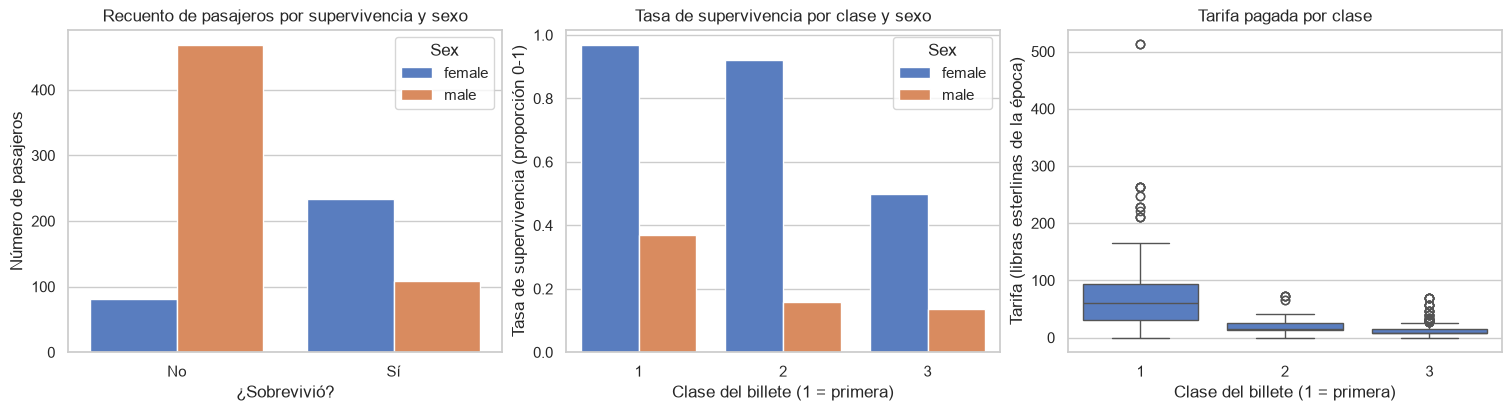

In [22]:
fig_sns, axs = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")

# 1. Recuento (no es una tasa)
sns.countplot(data=titanic, x="Survived_label", hue="Sex", hue_order=["female", "male"], ax=axs[0])
axs[0].set_title("Recuento de pasajeros por supervivencia y sexo")
axs[0].set_xlabel("¿Sobrevivió?")
axs[0].set_ylabel("Número de pasajeros")

# 2. Tasa = media de 0/1
sns.barplot(data=titanic, x="Pclass", y="Survived", hue="Sex", hue_order=["female", "male"], errorbar=None, ax=axs[1])
axs[1].set_title("Tasa de supervivencia por clase y sexo")
axs[1].set_xlabel("Clase del billete (1 = primera)")
axs[1].set_ylabel("Tasa de supervivencia (proporción 0-1)")

# 3. Tarifa por clase
sns.boxplot(data=titanic, x="Pclass", y="Fare", ax=axs[2])
axs[2].set_title("Tarifa pagada por clase")
axs[2].set_xlabel("Clase del billete (1 = primera)")
axs[2].set_ylabel("Tarifa (libras esterlinas de la época)")

plt.show()

In [23]:
assert len(axs) == 3
assert len(axs[0].patches) >= 2
assert len(axs[1].patches) >= 1
assert len(axs[2].patches) >= 1
print("Seaborn: comprobación superada")

Seaborn: comprobación superada


## 2. Plotly — una exploración interactiva

Crea `fig_plotly` con `px.scatter`:

- X: `Age`.
- Y: `Fare`.
- Color: `Survived_label`.
- `hover_data=["Sex", "Pclass", "Embarked"]`.
- Título, transparencia y ejes con unidades: edad en años y tarifa en libras esterlinas.

Después exporta un HTML autónomo:

```python
fig_plotly.write_html("titanic_interactivo.html", include_plotlyjs=True, full_html=True)
```

Abre el HTML en el navegador y prueba hover, ocultar/mostrar un grupo en la leyenda, zoom y restauración. No basta con que el archivo exista.

Faltan 177 edades: esta dispersión tiene 714 registros con Age y Fare presentes, no 891. No imputes edades solo para completar el dibujo.


In [24]:
fig_plotly = px.scatter(
    titanic,
    x="Age",
    y="Fare",
    color="Survived_label",
    hover_data=["Sex", "Pclass", "Embarked"],
    opacity=0.6,
    title="Edad y tarifa de los pasajeros del Titanic según supervivencia",
    labels={
        "Age": "Edad (años)",
        "Fare": "Tarifa (libras esterlinas)",
        "Survived_label": "¿Sobrevivió?",
    },
)
fig_plotly.write_html("titanic_interactivo.html", include_plotlyjs=True, full_html=True)
print("Puntos dibujados (Age y Fare presentes):", titanic[["Age", "Fare"]].dropna().shape[0])
fig_plotly.show()

Puntos dibujados (Age y Fare presentes): 714


In [25]:
from pathlib import Path
import re
html = Path("titanic_interactivo.html")
assert html.exists()
contenido = html.read_text(encoding="utf-8")
assert "Plotly.newPlot" in contenido and "plotly.js" in contenido
assert not re.search(r'<script\b[^>]*\bsrc\s*=', contenido, flags=re.IGNORECASE)
print("HTML autónomo generado. Falta comprobar y registrar hover, leyenda y zoom en el navegador.")

HTML autónomo generado. Falta comprobar y registrar hover, leyenda y zoom en el navegador.


## 3. EDA — tasa de supervivencia y nulos

Calcula:

- `pivot = titanic.pivot_table(index="Pclass", columns="Sex", values="Survived", aggfunc="mean")`.
- `nulos`: los nulos por columna, ordenados de mayor a menor.
- `tasa`: la tasa global de supervivencia.

**Salida esperada:** una tabla 3×2; `Age` y `Cabin` con muchos nulos; tasa global en torno a 0,38.


In [26]:
pivot = titanic.pivot_table(index="Pclass", columns="Sex", values="Survived", aggfunc="mean")
nulos = titanic.isna().sum().sort_values(ascending=False)
tasa = titanic["Survived"].mean()

print(pivot.round(3))
print()
print(nulos[nulos > 0])
print()
print(f"Tasa global de supervivencia: {tasa:.3f}")

Sex     female   male
Pclass               
1        0.968  0.369
2        0.921  0.157
3        0.500  0.135

Cabin       687
Age         177
Embarked      2
dtype: int64

Tasa global de supervivencia: 0.384


In [27]:
assert pivot.shape == (3, 2)
assert pivot.loc[1, "female"] > pivot.loc[3, "female"]
assert nulos.loc["Age"] == 177 and nulos.loc["Cabin"] == 687
assert np.isclose(tasa, titanic["Survived"].mean())
assert 0.3 < tasa < 0.45
print("EDA: comprobación superada")

EDA: comprobación superada


## 3b. Tres conclusiones

Escribe aquí, en tres frases:

1. Qué patrón de supervivencia se observa por sexo y clase.
2. Qué columnas tienen nulos y qué implica para el análisis.
3. Qué limitación tiene este dataset (muestra, sesgo, variables ausentes).

**Respuesta:**

1. **Sexo y clase.** La supervivencia depende mucho de ambos. La tasa global es 0,38, pero llega a 0,74 en mujeres frente a 0,19 en hombres, y baja con la clase (0,63 en primera, 0,47 en segunda y 0,24 en tercera). Combinados, casi todas las mujeres de primera (0,97) y segunda (0,92) sobrevivieron, mientras que solo el 0,14 de los hombres de tercera lo hizo.
2. **Nulos.** `Cabin` tiene 687 nulos (77 %), `Age` 177 (20 %) y `Embarked` 2. `Cabin` es casi inutilizable tal cual; con `Age` conviene decidir si se excluye (como en el gráfico de Plotly, con 714 puntos) o se imputa (como en la preparación para ML), sabiendo que imputar con la mediana reduce la variabilidad real de la edad.
3. **Limitación.** Son 891 pasajeros, un subconjunto de los que viajaban (la tripulación está ausente y no hay muestreo aleatorio), y las diferencias observadas son asociaciones: clase, sexo y tarifa están relacionadas entre sí y con la ubicación en el barco o las normas de evacuación, variables que no están en los datos. Por eso no se pueden interpretar como causas.

## 4. Preparación para ML — ampliación guiada si se llega

No es obligatorio terminarlo hoy para registrar seguimiento. Si todavía estás con gráficos/EDA/HTML, continúa esos apartados y marca este como pendiente.

Objetivo: practicar el orden de `fit_transform` sobre train y `transform` sobre test. El EDA anterior usa todo el CSV como ejercicio descriptivo: esta división posterior **no** convertiría sus decisiones en una evaluación independiente. Cuando se evalúen modelos, se reservará test antes de explorar y elegir transformaciones.

Pasos:

1. Elimina `PassengerId`, `Name`, `Ticket`, `Cabin`, `Survived` y `Survived_label` de `X`.
2. Define `y = titanic["Survived"]`.
3. Separa train/test con `train_test_split(..., test_size=0.2, stratify=y, random_state=42)`.
4. Numéricas: `Age`, `Fare`, `SibSp`, `Parch` → imputar mediana y escalar.
5. Categóricas: `Pclass`, `Sex`, `Embarked` → imputar moda y `OneHotEncoder(sparse_output=False, handle_unknown="ignore")`.
6. Ajusta el `ColumnTransformer` **solo con train**; transforma train y test.

Se da una plantilla: completa las dos listas de columnas y explica por qué se separa antes de aprender medianas, categorías y escalas. `Pclass` es una categoría aunque sus valores sean números. Eliminar Name/Ticket/Cabin es una simplificación de este primer ejemplo, no una regla universal.

**Salida esperada:** `X_train_prep` con 712 filas y `X_test_prep` con 179; 12 columnas y sin NaN en ambas. No se entrena ningún modelo.


In [28]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

X = titanic.drop(columns=["PassengerId", "Name", "Ticket", "Cabin", "Survived", "Survived_label"])
y = titanic["Survived"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

numericas = ["Age", "Fare", "SibSp", "Parch"]
categoricas = ["Pclass", "Sex", "Embarked"]

preprocesado = ColumnTransformer([
    ("num", Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler())]), numericas),
    ("cat", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")), ("codificar", OneHotEncoder(sparse_output=False, handle_unknown="ignore"))]), categoricas),
])
X_train_prep = preprocesado.fit_transform(X_train)
X_test_prep = preprocesado.transform(X_test)
print(X_train_prep.shape, X_test_prep.shape)


(712, 12) (179, 12)


In [29]:
assert X_train_prep.shape[0] == len(X_train)
assert X_test_prep.shape[0] == len(X_test)
assert X_train_prep.shape == (712, 12) and X_test_prep.shape == (179, 12)
assert np.isfinite(np.asarray(X_train_prep)).all()
assert np.isfinite(np.asarray(X_test_prep)).all()
assert {"Survived", "Survived_label"}.isdisjoint(X.columns)
assert set(X_train.index).isdisjoint(X_test.index)
print("ML prep: comprobación superada;", X_train_prep.shape[1], "columnas tras el preprocesado")

ML prep: comprobación superada; 12 columnas tras el preprocesado


**¿Por qué se separa antes de aprender medianas, categorías y escalas?** Las medianas, las modas, las categorías del `OneHotEncoder` y las medias y desviaciones del `StandardScaler` se aprenden de los datos. Si se calcularan con todo el CSV, el test influiría en el preprocesado y la evaluación posterior sería demasiado optimista (fuga de información). Por eso `fit_transform` se hace solo con `X_train` y el test se limita a `transform`.

## 5. Reto y clínica de pandas

Si terminas antes:

- Añade una tabla de puertos con `merge`:

```python
puertos = pd.DataFrame({
    "Embarked": ["C", "Q", "S"],
    "puerto": ["Cherbourg", "Queenstown", "Southampton"],
})
titanic.merge(puertos, on="Embarked", how="left")
```

- Calcula la tasa de supervivencia por `Embarked` y `Pclass` con `groupby`.
- Prueba `pairplot` con variables numéricas como Age y Fare y `hue="Survived_label"`; no construyas una matriz numérica con Sex como si fuera una medida.

No es obligatorio para la entrega base.


Pclass                       1         2         3
Embarked puerto                                   
C        Cherbourg    0.694118  0.529412  0.378788
Q        Queenstown   0.500000  0.666667  0.375000
S        Southampton  0.582677  0.463415  0.189802


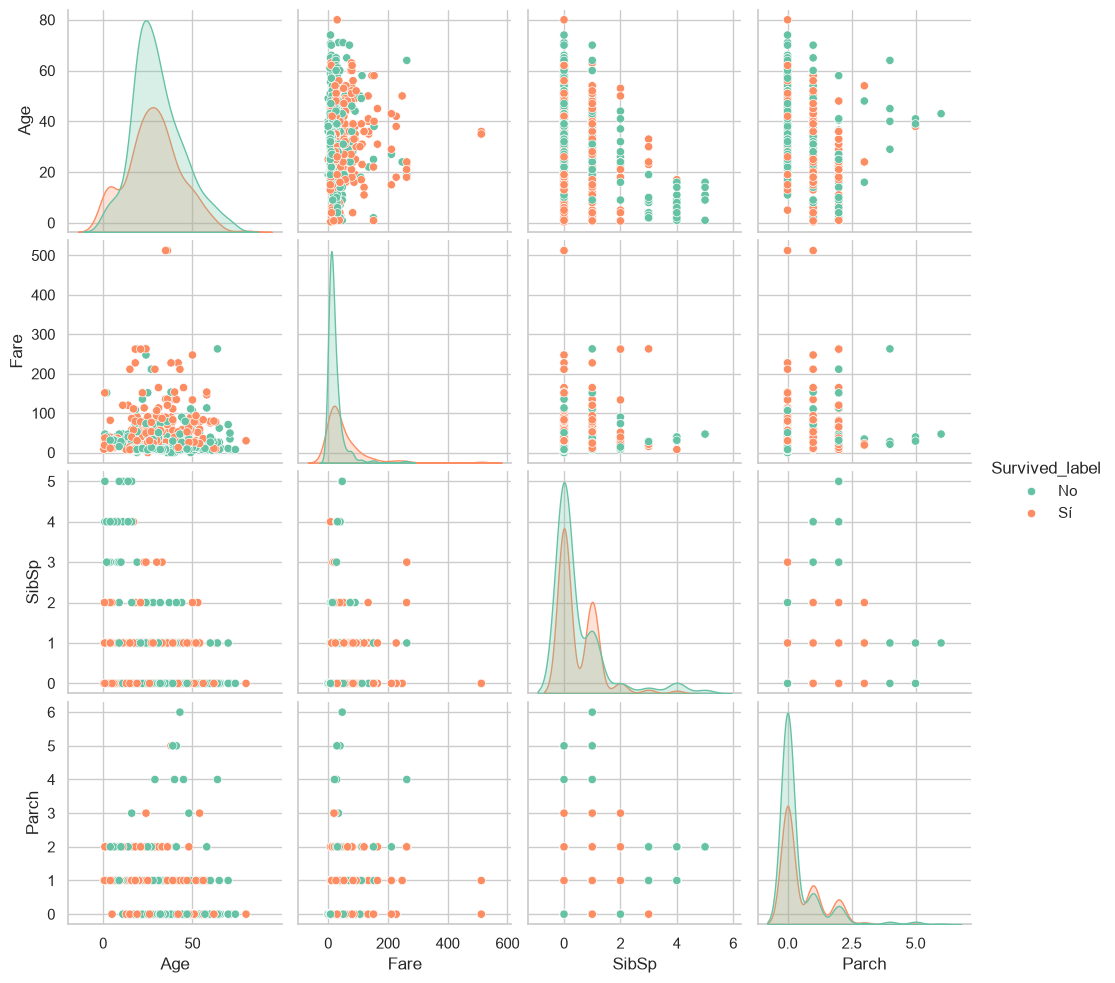

In [36]:
puertos = pd.DataFrame({
    "Embarked": ["C", "Q", "S"],
    "puerto": ["Cherbourg", "Queenstown", "Southampton"],
})

# Elimina 'puerto' si ya existía para evitar el duplicado
titanic = titanic.drop(columns=['puerto'], errors='ignore')

# Ahora el merge funciona limpiamente
titanic = titanic.merge(puertos, on="Embarked", how="left")
titanic
# Tasa de supervivencia media agrupada por puerto y clase
tasa_supervivencia = titanic.groupby(["Embarked", "puerto", "Pclass"])["Survived"].mean().reset_index()

# Opcional: mostrarlo en formato de tabla pivote para mayor claridad visual
tabla_pivote = titanic.pivot_table(index=["Embarked", "puerto"], columns="Pclass", values="Survived", aggfunc="mean")
print(tabla_pivote)

# Filtramos o seleccionamos únicamente las columnas numéricas de interés + la etiqueta de supervivencia
columnas_pairplot = ['Age', 'Fare', 'SibSp', 'Parch', 'Survived_label']

# Es recomendable limpiar nulos previos para evitar errores en el gráfico
sns.pairplot(titanic[columnas_pairplot].dropna(), hue="Survived_label", palette="Set2")
plt.show()

## 6. Ticket de salida

**Interpretación de los gráficos de Seaborn**

- **Recuento por sexo:** hay muchos más hombres que mujeres y, entre los no supervivientes, predominan los hombres (468 frente a 81). Es un recuento: refleja que hay más hombres a bordo, no que tengan menos probabilidad.
- **Tasa por clase y sexo:** la tasa cae al bajar de clase en ambos sexos, y la diferencia entre mujeres y hombres es grande en las tres clases (0,97 frente a 0,37 en primera, 0,50 frente a 0,14 en tercera).
- **Tarifa por clase:** la mediana sube con la clase (unas 60 libras en primera, 14 en segunda, 8 en tercera) y la primera tiene outliers muy altos, hasta unas 512 libras, lo que sesga la media.

Después registra lo probado en el HTML:

| Prueba | Qué ocurrió realmente |
|---|---|
| Hover sobre un punto | Al pasar el ratón sobre un punto aparece un cuadro con la edad, la tarifa, el sexo, la clase, el puerto de embarque y si sobrevivió. |
| Ocultar/mostrar un grupo en la leyenda | Al hacer clic en «No» desaparecen los puntos de quienes no sobrevivieron y quedan solo los de «Sí». Al volver a hacer clic reaparecen. |
| Zoom y restauración | Al arrastrar un rectángulo el gráfico se amplía a esa zona. Con doble clic vuelve a la vista completa. |

1. ¿Qué diferencia hay entre `countplot` y `barplot(y="Survived")`?
2. ¿Qué aporta Plotly frente a Seaborn? ¿Cuándo no lo usarías?
3. ¿Qué columnas eliminarías antes de modelar y por qué?
4. ¿Dónde se ajusta el preprocesador para no filtrar información del test?
5. ¿Qué limitación tiene el dataset?

Si no se ha trabajado ML, marca las preguntas 3–4 como pendientes y responde las demás.

**Respuestas:**

1. `countplot` cuenta filas por categoría (un recuento absoluto, que depende de cuántos pasajeros hay en cada grupo). `barplot(y="Survived")` calcula la media de una variable 0/1 por grupo, es decir, una proporción o tasa de supervivencia, comparable entre grupos de distinto tamaño.
2. Plotly permite explorar: hover con datos de cada punto, filtrar por leyenda, zoom y un HTML que se comparte sin Python. Seaborn es más rápido para figuras estáticas y estadísticas. No usaría Plotly en un informe impreso o PDF, con muchísimos puntos (rendimiento) o cuando la figura solo tiene que mostrar un mensaje fijo.
3. `PassengerId` (identificador sin información), `Name` y `Ticket` (texto casi único por pasajero), `Cabin` (77 % de nulos), y sobre todo `Survived` y `Survived_label`, que son la variable objetivo y generarían fuga de información (data leakage). Es una simplificación: de `Name` se podría extraer el título.
4. Solo con los datos de entrenamiento (`fit_transform` sobre `X_train`); el test solo se transforma con `transform`. Así medianas, modas, categorías y escalas no incorporan información del test.
5. Es una muestra de 891 pasajeros sin tripulación y con nulos importantes; las variables clase, sexo y tarifa están correlacionadas y no recogen factores como la ubicación en el barco, así que las asociaciones no prueban causalidad.

## 7. Registro de entrega

| Apartado | Completo / en curso / pendiente | Qué he probado o qué falta |
|---|---|---|
| Preparación del entorno | Completo | Celda de preparación ejecutada con 891 filas. Ejecutado con el Python de la máquina de preparación |
| Seaborn: tres gráficos | Completo | Tres paneles con título, ejes y unidades; checkpoint superado. |
| Plotly: HTML comprobado | Completo | HTML autónomo generado y checkpoint superado. |
| EDA y conclusiones | Completo | Tabla 3×2, nulos y tasa global (0,384); tres conclusiones escritas. |
| Preparación para ML | Completo | 712×12 y 179×12, sin NaN; preprocesador ajustado solo con train. |

**Ayuda utilizada (documentación, pareja, IA):** El trabajo fue realizado por el alumno con ayuda de documentación y ejercicios pasados, y uso de IA unicamente en caso puntuales (Normalmente errores sintaxis)

**Antes de entregar:** reinicia el kernel y ejecuta en orden los apartados completados; conserva las salidas. Si uno no se ha iniciado, no ejecutes su checkpoint: anota pendiente. Comprueba la estructura del ZIP en [entrega-titanic.md](entrega-titanic.md).